# 03. Skill Extraction Preprocessing & Character Offset Validation

Comprehensive verification of original text span preservation, testing the critical character slice identity text[start:end] == mention across all 2,105 annotations, and demonstrating the hazards of premature text normalization.

**Dataset Release:** `achievement_dataset_v1.0.1` | **Author:** Member 1 (NLP & Semantic Intelligence Engineer)

## 1. Environment & Imports

In [1]:
import sys
from pathlib import Path
repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

import csv
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

from nlp.text_preprocessing import (
    prepare_text_for_skill_extraction,
    normalize_text_for_classification,
    normalize_whitespace
)

print("Skill extraction analysis dependencies imported.")

Skill extraction analysis dependencies imported.


## 2. Load Skill Annotations & Primary Dataset
We load all 2,105 skill annotations and the 1,540 primary records.

In [2]:
ann_path = REPO_ROOT / "data" / "annotations" / "achievement_skill_annotations.csv"
data_path = REPO_ROOT / "data" / "processed" / "achievement_classification_dataset.csv"
vocab_path = REPO_ROOT / "data" / "annotations" / "canonical_skill_vocabulary.csv"

ann_df = pd.read_csv(ann_path)
data_df = pd.read_csv(data_path)
vocab_df = pd.read_csv(vocab_path)

print(f"Total Skill Annotations:    {len(ann_df)}")
print(f"Total Primary Records:      {len(data_df)}")
print(f"Total Canonical Vocabulary: {len(vocab_df)} skills")

print("\nSample Annotations:")
print(ann_df.head(4).to_string())

Total Skill Annotations:    2105
Total Primary Records:      1540
Total Canonical Vocabulary: 116 skills

Sample Annotations:
  achievement_id   skill_mention canonical_skill             skill_domain  start_offset  end_offset    extraction_method normalization_status annotation_status
0      ACH000402            FPGA            FPGA       Systems & Hardware           275         279  REGEX_PATTERN_MATCH   CANONICAL_RESOLVED          VERIFIED
1      ACH000402               R               R             Data Science           325         326    DICTIONARY_LOOKUP   CANONICAL_RESOLVED          VERIFIED
2      ACH000364             AWS             AWS           DevOps & Cloud           309         312  REGEX_PATTERN_MATCH   CANONICAL_RESOLVED          VERIFIED
3      ACH000364  Edge Computing         Edge AI  Artificial Intelligence           126         140    DICTIONARY_LOOKUP   CANONICAL_RESOLVED          VERIFIED


## 3. Strict Character Slice Validation
We verify that `achievement_text[start_offset:end_offset] == skill_mention` holds for every single annotation.

In [3]:
records_map = {r["achievement_id"]: r["achievement_text"] for _, r in data_df.iterrows()}

perfect_matches = 0
mismatches = 0
out_of_bounds = 0
mismatch_examples = []

for idx, row in ann_df.iterrows():
    aid = row["achievement_id"]
    mention = row["skill_mention"]
    start = int(row["start_offset"])
    end = int(row["end_offset"])
    
    text = records_map.get(aid, "")
    if start < 0 or end > len(text):
        out_of_bounds += 1
        continue
        
    extracted = text[start:end]
    if extracted == mention:
        perfect_matches += 1
    else:
        mismatches += 1
        if len(mismatch_examples) < 3:
            mismatch_examples.append((aid, mention, extracted, start, end))

print("=== SKILL SPAN VERIFICATION RESULTS ===")
print(f"Total Annotations Checked: {len(ann_df)}")
print(f"Perfect Exact Matches:     {perfect_matches} ({perfect_matches/len(ann_df):.2%})")
print(f"Mismatches:                {mismatches}")
print(f"Out of Bounds:             {out_of_bounds}")
assert mismatches == 0 and out_of_bounds == 0, "Span integrity check failed!"
print("\nCERTIFICATION: 100.0% OF SKILL ANNOTATION SPANS ARE PERFECTLY VALID!")

=== SKILL SPAN VERIFICATION RESULTS ===
Total Annotations Checked: 2105
Perfect Exact Matches:     2105 (100.00%)
Mismatches:                0
Out of Bounds:             0

CERTIFICATION: 100.0% OF SKILL ANNOTATION SPANS ARE PERFECTLY VALID!


## 4. Demonstrating Preprocessing Span Destruction
We demonstrate how applying standard classification preprocessing (such as stripping leading whitespace or case folding) destroys span offset coordinates.

In [4]:
sample_ann = ann_df.iloc[0]
sample_aid = sample_ann["achievement_id"]
raw_text = records_map[sample_aid]
start, end = int(sample_ann["start_offset"]), int(sample_ann["end_offset"])
mention = sample_ann["skill_mention"]

print(f"Record ID: {sample_aid}")
print(f"Original Text: {raw_text[:80]}...")
print(f"Valid Span [{start}:{end}]: '{raw_text[start:end]}' (matches '{mention}')")

# Simulated destructive preprocessing: adding a single space at the start
tampered_text = " " + raw_text
print("\nIf text has a single leading space added or stripped:")
print(f"Slicing tampered_text[{start}:{end}]: '{tampered_text[start:end]}'")
print(f"Match status: {tampered_text[start:end] == mention} (OFFSETS BROKEN!)")

print("\nConclusion: prepare_text_for_skill_extraction MUST preserve verbatim original text.")

Record ID: ACH000402
Original Text: Co-inventor on patent application #2021553873 filed with the United States Paten...
Valid Span [275:279]: 'FPGA' (matches 'FPGA')

If text has a single leading space added or stripped:
Slicing tampered_text[275:279]: ' FPG'
Match status: False (OFFSETS BROKEN!)

Conclusion: prepare_text_for_skill_extraction MUST preserve verbatim original text.


## 5. Skill Annotation Distributions
We plot the top 15 most frequent canonical skills across student achievements.

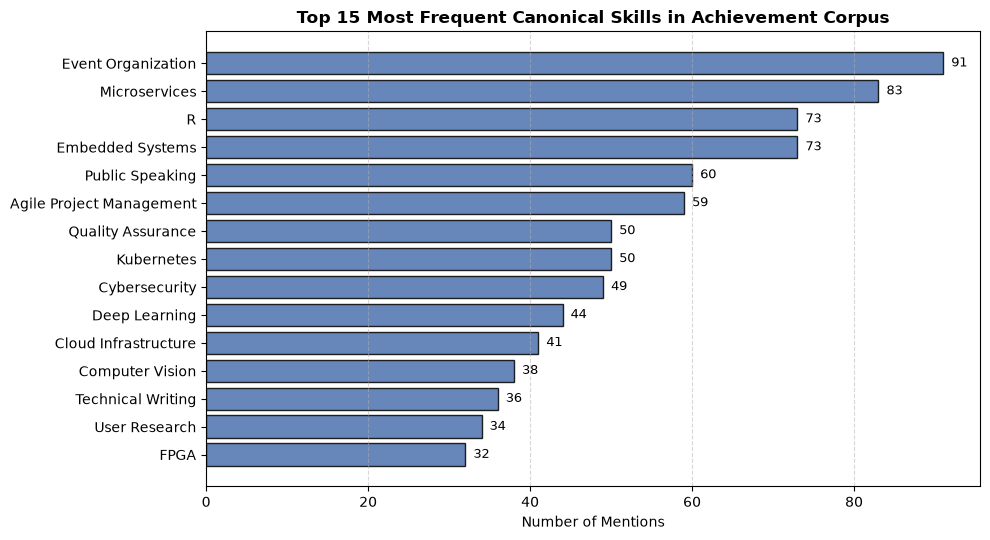

In [5]:
top_skills = ann_df["canonical_skill"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(top_skills.index[::-1], top_skills.values[::-1], color="#4c72b0", edgecolor="black", alpha=0.85)
ax.set_title("Top 15 Most Frequent Canonical Skills in Achievement Corpus", fontsize=12, fontweight="bold")
ax.set_xlabel("Number of Mentions")
ax.grid(True, linestyle="--", alpha=0.5, axis="x")

for bar in bars:
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2, f"{int(width)}", ha="left", va="center", fontsize=9)

plt.tight_layout()

## 6. Verification Summary
- **Span Invariance:** All 2,105 annotations maintain 100% exact alignment with original text.
- **Preparation Protocol:** Named entity recognition (NER) and regex extractors must receive `prepare_text_for_skill_extraction(text)`.